# Correctness validation

Run the correctness checker twice on its controlled demo fixtures, using the same seed and corruption rates. Compare the generated artifacts, then check the observed results against the fixture expectations.

Run all cells in a Python 3 kernel with Matplotlib and Seaborn installed. The notebook finds the repository from its root or the `notebooks/` directory. The demo runs offline on 20 fixtures and writes reports to temporary directories.

In [1]:
import json
import subprocess
import sys
from math import isclose
from pathlib import Path
from tempfile import TemporaryDirectory

cwd = Path.cwd()
repo_root = next(
    (path for path in (cwd, *cwd.parents)
     if (path / "validation" / "correctness_checker.py").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Start the notebook from the repository root or notebooks directory.")

seed = 42
rates = (0, 0.1, 0.25, 0.5, 1)
artifact_names = ("manifest.json", "report.json", "summary.csv", "report.md")


def run_demo(output_dir):
    command = [
        sys.executable, "-m", "validation.correctness_checker",
        "--demo", "--seed", str(seed), "--rates", *map(str, rates),
        "--output", str(output_dir),
    ]
    run = subprocess.run(command, cwd=repo_root, capture_output=True, text=True)
    if run.returncode:
        raise RuntimeError(
            f"Correctness checker exited with {run.returncode}\n{run.stdout}{run.stderr}"
        )
    return {name: (output_dir / name).read_bytes() for name in artifact_names}


with TemporaryDirectory(prefix="correctness-validation-") as directory:
    first_run = run_demo(Path(directory) / "first")
    second_run = run_demo(Path(directory) / "second")

different = [name for name in artifact_names if first_run[name] != second_run[name]]
assert not different, f"Artifacts differ across runs: {different}"
print(f"Two runs with seed {seed} produced byte-identical artifacts.")
print(", ".join(artifact_names))
report = json.loads(first_run["report.json"])

Two runs with seed 42 produced byte-identical artifacts.
manifest.json, report.json, summary.csv, report.md


## Validate the controlled results

Each clean fixture passes all four checks. An unknown tool or a wrong argument type fails two checks. A missing entity or broken precondition fails one. At each rate, the expected dataset score is 1 minus the fraction of corrupted fixtures multiplied by the fraction of checks those fixtures should fail.

In [2]:
task_count = 20
failed_checks_per_corruption = {
    "broken_precondition": 1,
    "missing_entity": 1,
    "unknown_tool": 2,
    "wrong_type": 2,
}

assert report["status"] == "pass" and report["passed"]
assert report["seed"] == seed
assert report["task_count"] == report["clean_labeled_tasks"] == task_count
assert report["baseline_score"] == 1
assert report["baseline_false_positive_rate"] == 0

campaigns = report["campaigns"]
expected_cases = {(kind, rate) for kind in failed_checks_per_corruption for rate in rates}
assert len(campaigns) == len(expected_cases)
assert {(row["kind"], row["requested_rate"]) for row in campaigns} == expected_cases

for row in campaigns:
    kind, rate = row["kind"], row["requested_rate"]
    case = f"{kind} at {rate:.0%} corruption"
    corrupted_count = int(task_count * rate + 0.5)
    expected_score = 1 - (corrupted_count / task_count) * (failed_checks_per_corruption[kind] / 4)

    assert row["eligible_tasks"] == task_count, case
    assert row["corrupted_tasks"] == corrupted_count, case
    assert row["detected"] == row["targeted_detected"] == corrupted_count, case
    assert row["expected_check_vectors_matched"] == corrupted_count, case
    assert row["false_positives"] == 0, case
    assert isclose(row["observed_score"], expected_score, rel_tol=0, abs_tol=1e-12), case
    assert isclose(row["expected_score"], expected_score, rel_tol=0, abs_tol=1e-12), case

print(f"Validated {len(campaigns)} campaign and rate combinations across {task_count} fixtures.")
print("Every injected corruption was detected and no clean fixtures were flagged.")

Validated 20 campaign and rate combinations across 20 fixtures.
Every injected corruption was detected and no clean fixtures were flagged.


## Observed and expected scores

The Seaborn points show the observed scores. The dashed Matplotlib lines show the expected scores. The panels share a scale so the impact of each corruption can be compared directly.

Matplotlib is building the font cache; this may take a moment.


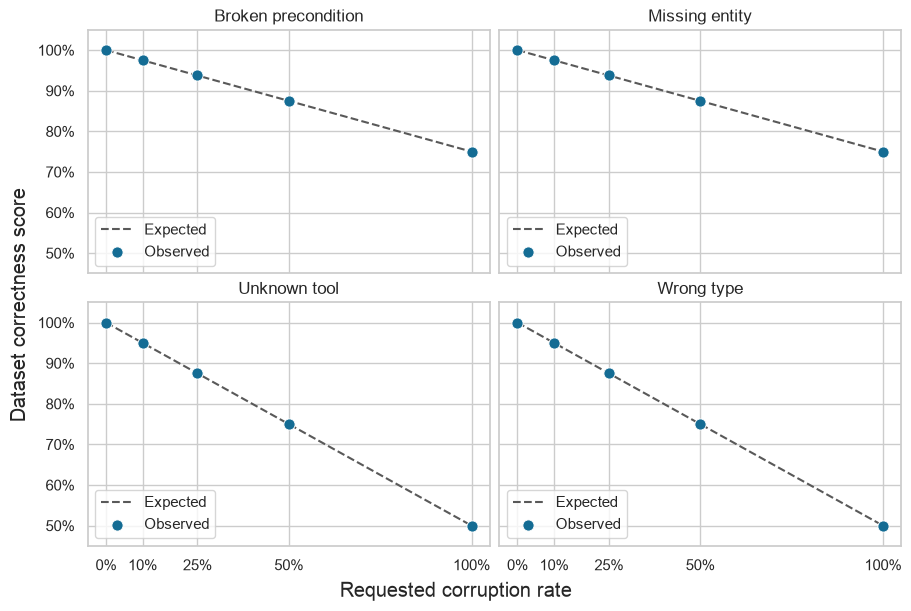

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, sharex=True, sharey=True, figsize=(9, 6), layout="constrained")

for ax, kind in zip(axes.flat, failed_checks_per_corruption):
    rows = sorted(
        (row for row in campaigns if row["kind"] == kind),
        key=lambda row: row["requested_rate"],
    )
    x = [row["requested_rate"] for row in rows]
    ax.plot(x, [row["expected_score"] for row in rows],
            linestyle="--", color="0.35", label="Expected")
    sns.scatterplot(x=x, y=[row["observed_score"] for row in rows],
                    ax=ax, color="#146c94", s=65, label="Observed", zorder=3)
    ax.set_title(kind.replace("_", " ").capitalize())
    ax.set(xticks=rates, ylim=(0.45, 1.05))
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.legend(loc="lower left")

fig.supxlabel("Requested corruption rate")
fig.supylabel("Dataset correctness score")
plt.show()